In [1]:
!pip install datasets -q

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the uploaded dataset
df = pd.read_csv("sentiment_reviews (1).csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head(10))

Dataset loaded successfully!
Dataset shape: (10, 3)


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative
5,6,Customer support helped resolve my setup quest...,positive
6,7,Delivery was slow and package was missing one ...,negative
7,8,Clean interface and intuitive controls. Highly...,positive
8,9,"Not worth the money, plenty of better alternat...",negative
9,10,Great value and durable build. Would definitel...,positive


Sentiment counts:
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64


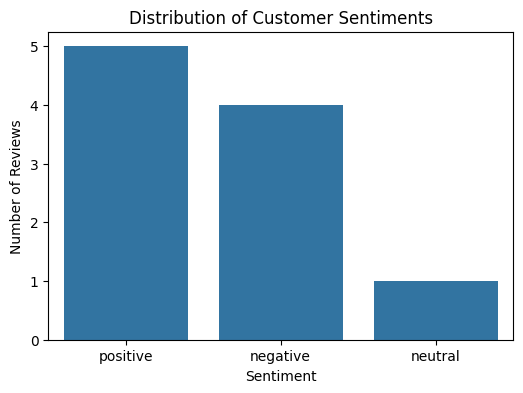

In [5]:

print("Sentiment counts:")
print(df["sentiment"].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="sentiment")

plt.title("Distribution of Customer Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [6]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSentiment categories:")
print(df["sentiment"].unique())

Missing values:
review_id      0
review_text    0
sentiment      0
dtype: int64

Duplicate rows: 0

Sentiment categories:
['positive' 'negative' 'neutral']


In [7]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["cleaned_review"] = df["review_text"].apply(clean_text)

display(df[["review_text", "cleaned_review", "sentiment"]])

,review_text,cleaned_review,sentiment
0,"The product quality is exceptional, exceeded a...",the product quality is exceptional exceeded al...,positive
1,Terrible customer service and the item arrived...,terrible customer service and the item arrived...,negative
2,"Average performance, decent for the price poin...",average performance decent for the price point...,neutral
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love this easy to setup robust and ...,positive
4,Stopped working after two days. Extremely disa...,stopped working after two days extremely disap...,negative
5,Customer support helped resolve my setup quest...,customer support helped resolve my setup quest...,positive
6,Delivery was slow and package was missing one ...,delivery was slow and package was missing one ...,negative
7,Clean interface and intuitive controls. Highly...,clean interface and intuitive controls highly ...,positive
8,"Not worth the money, plenty of better alternat...",not worth the money plenty of better alternati...,negative
9,Great value and durable build. Would definitel...,great value and durable build would definitely...,positive


In [8]:
print("Original review:")
print(df["review_text"].iloc[0])

print("\nCleaned review:")
print(df["cleaned_review"].iloc[0])

Original review:
The product quality is exceptional, exceeded all my expectations!

Cleaned review:
the product quality is exceptional exceeded all my expectations


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words="english")

X = tfidf.fit_transform(df["cleaned_review"])

y = df["sentiment"]

print("TF-IDF transformation completed!")
print("Feature matrix shape:", X.shape)
print("Sentiment labels:", y.shape)

TF-IDF transformation completed!
Feature matrix shape: (10, 60)
Sentiment labels: (10,)


In [10]:
from sklearn.naive_bayes import MultinomialNB

# Create the Naive Bayes model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X, y)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [11]:
# Predict sentiment for existing reviews
y_pred = nb_model.predict(X)

results = pd.DataFrame({
    "Actual Sentiment": y,
    "Predicted Sentiment": y_pred
})

display(results)

,Actual Sentiment,Predicted Sentiment
0,positive,positive
1,negative,negative
2,neutral,positive
3,positive,positive
4,negative,negative
5,positive,positive
6,negative,negative
7,positive,positive
8,negative,negative
9,positive,positive


In [12]:
def predict_sentiment(review):
    cleaned_review = clean_text(review)

    review_vector = tfidf.transform([cleaned_review])

    prediction = nb_model.predict(review_vector)

    return prediction[0]

# Test the function
print(predict_sentiment("This product is excellent and amazing!"))

print(predict_sentiment("I am very disappointed with this product."))

positive
positive


In [13]:
test_reviews = [
    "The product is wonderful and I love it.",
    "The quality is poor and I am unhappy.",
    "The product is average and acceptable."
]

for review in test_reviews:
    print("Review:", review)
    print("Predicted sentiment:", predict_sentiment(review))
    print("-" * 50)

Review: The product is wonderful and I love it.
Predicted sentiment: positive
--------------------------------------------------
Review: The quality is poor and I am unhappy.
Predicted sentiment: positive
--------------------------------------------------
Review: The product is average and acceptable.
Predicted sentiment: positive
--------------------------------------------------


##Task 4: NLP Sentiment Classification

#Objective

The objective of this project is to develop a Natural Language Processing (NLP) model that analyses customer reviews and classifies them into positive, negative, and neutral sentiments.

#Dataset

The project uses a customer reviews dataset containing review text and corresponding sentiment labels. The dataset includes three sentiment categories: positive, negative, and neutral.

#Text Preprocessing

The following preprocessing steps were performed:

Converted text into lowercase.

Removed punctuation and special characters.

Removed extra spaces.

Created a cleaned review column.

#Feature Extraction

TF-IDF (Term Frequency-Inverse Document Frequency) was used to convert text reviews into numerical features for machine learning.

#Machine Learning Model

A Multinomial Naive Bayes classifier was implemented to classify customer reviews into sentiment categories.

#Sentiment Prediction

A custom prediction function was developed to accept new customer reviews and predict their sentiment.

#Testing and Limitations

The model was tested using sample customer reviews. Since the dataset contains only 10 records, the results are intended to demonstrate the NLP workflow and should not be considered reliable measures of real-world predictive performance.

#Conclusion

This project demonstrates the application of NLP, text preprocessing, TF-IDF feature extraction, and Naive Bayes classification for customer sentiment analysis.